In [1]:
#file imports used
from PIL import Image
from bit_operators import BitFeederString, BitSaver
import os

In [2]:
#open a bmp and get its size
message="./sample.pptx"
cover="./stego.bmp"
filesize = os.path.getsize(message)
x = Image.open(cover)
pic_size = x.size
num_of_pixels = pic_size[0]*pic_size[1]
available_bytes=(num_of_pixels*(3))/8
print("Filesize="+str(filesize)+"\nCapacity="+str(int(available_bytes)))
if filesize > available_bytes:
    print("This is not going to work.")


Filesize=649158
Capacity=921600


In [3]:
def length_in_bits(length):
    bits = bin(length)[2:]
    bits = '0'*(32-len(bits)) + bits
    return bits
def length_in_int(binary_input):
    return int(binary_input, 2)

bfeed = BitFeederString(message)
length = bfeed.get_length()
print(length)
in_bits = length_in_bits(length)
print(in_bits)
print(len(in_bits))
in_int = length_in_int(in_bits)
print(in_int)

5193264
00000000010011110011111000110000
32
5193264


In [4]:
def bits2string(b=None):
    return ''.join([chr(int(x, 2)) for x in b])
#Makes sure we have an 8 bit byte from int
def byte_maker(color):
    return f'{color:08b}'
#returns an int from byte bin string
def int_maker(color):
    return int(color, 2)
#encodes however many bits specified
def encoder(cover,message,level=8):
    cover = cover[:level-1]+message+cover[level:]
    return cover
#Get file type
def get_type(input):
    type = os.path.splitext(input)
    output = str(type[-1])
    return output
name = get_type(message)
info = []
for letter in name:
    info.append(ord(letter))
print(info)
bits = ""
for stuff in info:
    print(byte_maker(stuff))
    bits += byte_maker(stuff)
print(bits)
bits = bits.zfill(40)
print(bits)
print(bits)
extension_length = len(bits)
print(extension_length)
new_list=["".join(bits[i:i + 8]) for i in range(0, len(bits), 8)]
output_string = bits2string(new_list)
output_string.split(".",1)[1] 
print(str(output_string))


[46, 112, 112, 116, 120]
00101110
01110000
01110000
01110100
01111000
0010111001110000011100000111010001111000
0010111001110000011100000111010001111000
0010111001110000011100000111010001111000
40
.pptx


In [5]:
#PIXELS ENCODED
encoded_length = length_in_bits(length)
length_index = 0
for i in range(pic_size[0]):
    for j in range(pic_size[1]):
        color = x.getpixel((i,j))
        modified = []
        #print("OG"+str(color))
        for RGB in range(len(color)):
                input = color[RGB]
                #print(str(input))
                cover = byte_maker(input)
                if length_index < 32:
                    message = encoded_length[length_index]
                    length_index +=1
                elif length_index >= 32 and length_index <72:
                    message = bits[length_index-32]
                    length_index +=1
                else:
                    message = bfeed.get_bits(1)
                #print(cover)
                #message = bfeed.get_bits(1)
                #print(message)
                encoded = encoder(cover,message,level=4)
                #print(encoded)
                output = int(encoded, 2)
                #print(output)
                modified.append(output)
        x.putpixel( (i , j), (modified[0], modified[1], modified[2], 255))
        #print("MOD"+str(x.getpixel((i,j))))
        if bfeed.finished == True:
            break

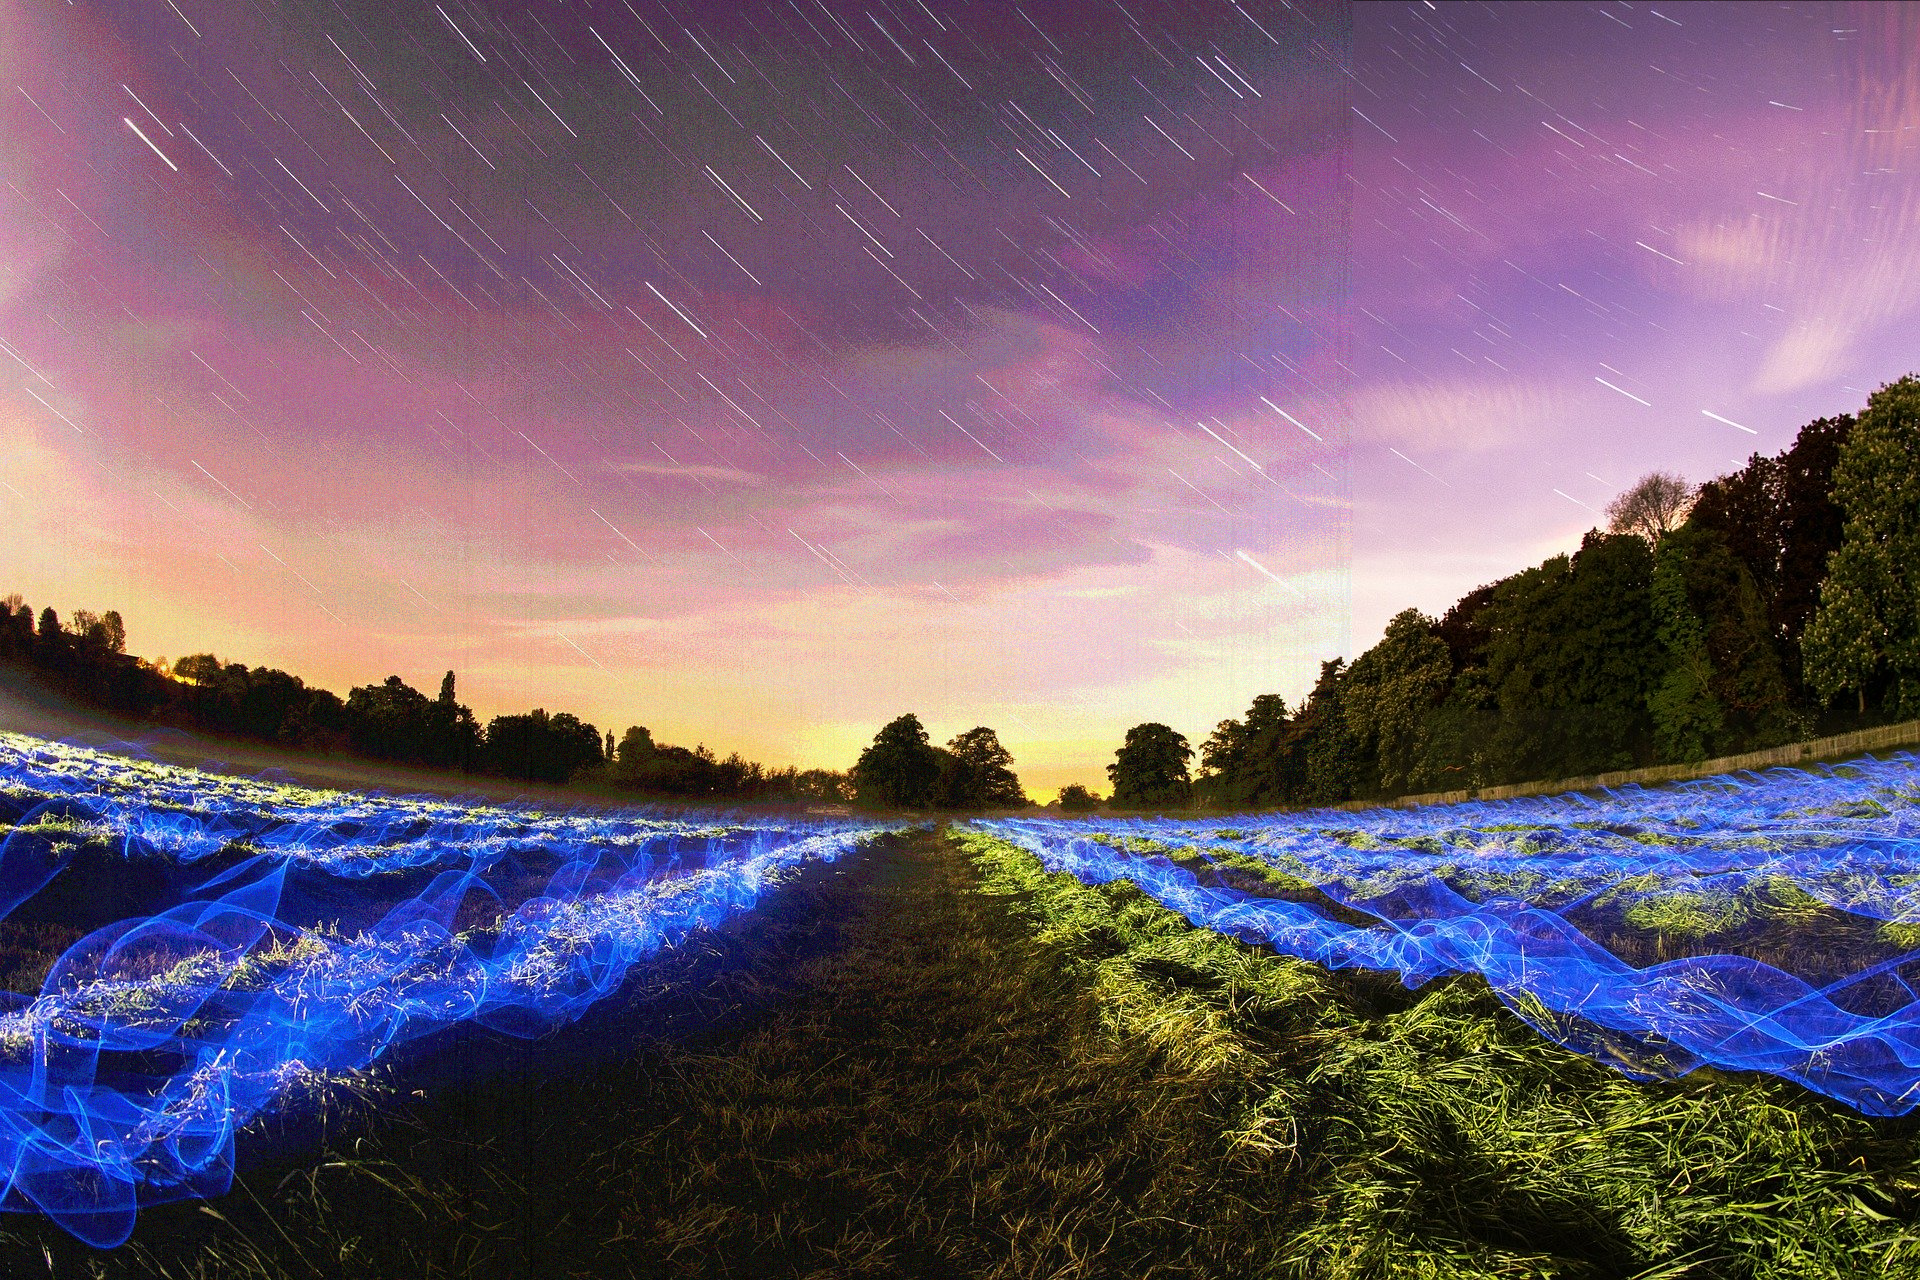

In [6]:
x

In [7]:
x.save("This_is_encoded.bmp", format="BMP")

In [8]:
x = Image.open("This_is_encoded.bmp")
bs = BitSaver(file_length=len(bfeed.bytes)*8)
print(len(bfeed.bytes)*8)

5193264


In [9]:
def decoder(cover,level=8):
    return cover[level-1:level]

def get_length_from_file(x:Image,level=8):
    i = 0
    message_length_string = ''
    for j in range(11):
        if index < 32:
            color = x.getpixel((i,j))
            for RGB in range(len(color)):
                output=byte_maker(color[RGB])
                    #print(output)
                bit = decoder(output,level=level)
                message_length_string = message_length_string + bit
    print(message_length_string)
    message_length_string = message_length_string[:32]
    return(length_in_int(message_length_string)+72)

def get_extension_from_file(x:Image,level=8):
    i = 0
    bit_string = ''
    for j in range(25):
            color = x.getpixel((i,j))
            for RGB in range(len(color)):
                output=byte_maker(color[RGB])
                    #print(output)
                bit = decoder(output,level=level)
                bit_string = bit_string + bit
    bit_string = bit_string[32:72]
    return bit_string

index = 0
finish = get_length_from_file(x,4)
print(finish)
type = get_extension_from_file(x,4)
new_list=["".join(type[i:i + 8]) for i in range(0, len(type), 8)]
output_string = bits2string(new_list)
extension = output_string.split(".",1)[1] 
print(extension)
for i in range(pic_size[0]):
    for j in range(pic_size[1]): 
        color = x.getpixel((i,j))
        for RGB in range(len(color)):
            if index < finish:
                output=byte_maker(color[RGB])
                #print(output)
                bit = decoder(output,level=4)
                if index < 72:
                    index+=1
                else:
                #print(bit)
                    bs.add_bits(bit)
                    index += 1
                #print(str(index)+ " " + str(bfeed.get_length()))
          

000000000100111100111110001100000
5193336
pptx


In [10]:
bs.save_file("output."+extension)